<a href="https://colab.research.google.com/github/Shreedevi-Shivashimpar/BB84-Simulation/blob/main/BB84_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install qiskit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 43.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.2 MB/s eta 0:00:00


In [4]:
import qiskit
print(qiskit.__version__)

2.5.2


In [5]:
import numpy as np
n=10
alice_bits=np.random.randint(0,2,n)
alice_bases=np.random.randint(0,2,n)
print("Alice's bits:",alice_bits)
print("Alice's bases:",alice_bases)

Alice's bits: [0 1 0 1 0 1 1 0 1 0]
Alice's bases: [0 0 1 1 0 1 0 1 0 1]


In [6]:
bob_bases=np.random.randint(0,2,n)
print("Bob's bases:",bob_bases)

Bob's bases: [1 1 0 1 0 0 0 1 1 0]


In [7]:
key=[]
for i in range(len(alice_bits)):
  if alice_bases[i]==bob_bases[i]:
    key.append(alice_bits[i])
print("Alice's key:",key)
print("Key length:",len(key))

Alice's key: [np.int64(1), np.int64(0), np.int64(1), np.int64(0)]
Key length: 4


In [8]:
import random
bob_bits=[]
for i in range(len(alice_bits)):
  if alice_bases[i]==bob_bases[i]:
    bob_bits.append(alice_bits[i])
  else:
    bob_bits.append(random.randint(0,1))
print("Alice's bits:",alice_bits)
print("Alice's_bases:",alice_bases)
print("Bob's bases:",bob_bases)
print("Bob's bits:",bob_bits)

Alice's bits: [0 1 0 1 0 1 1 0 1 0]
Alice's_bases: [0 0 1 1 0 1 0 1 0 1]
Bob's bases: [1 1 0 1 0 0 0 1 1 0]
Bob's bits: [1, 0, 0, np.int64(1), np.int64(0), 0, np.int64(1), np.int64(0), 1, 0]


In [9]:
alice_key=[]
bob_key=[]
for i in range(len(alice_bits)):
  if alice_bases[i]==bob_bases[i]:
    alice_key.append(alice_bits[i])
    bob_key.append(bob_bits[i])
print("Alice's sifted key:",alice_key)
print("Bob's sifted key:",bob_key)
print("Key length:",len(alice_key))

Alice's sifted key: [np.int64(1), np.int64(0), np.int64(1), np.int64(0)]
Bob's sifted key: [np.int64(1), np.int64(0), np.int64(1), np.int64(0)]
Key length: 4


In [10]:
errors=0
for i in range(len(alice_key)):
  if alice_key[i]!=bob_key[i]:
    errors+=1
if len(alice_key)>0:
  qber=(errors/len(alice_key))*100
  print("Total bits compared:",len(alice_key))
  print("Number of errors:",errors)
  print("QBER:",qber,"%")
else:
  print("No matching bases.Run the simulation again.")

Total bits compared: 4
Number of errors: 0
QBER: 0.0 %


In [11]:
eve_bases=[random.choice(['+','x'])for _ in range(n)]
eve_bits=[]
bob_bits_eve=[]
for i in range(n):
  if eve_bases[i]==alice_bases[i]:
    eve_bit=alice_bits[i]
  else:
    eve_bit=random.randint(0,1)
  if bob_bases[i]==eve_bases[i]:
    bob_bit=eve_bit
  else:
    bob_bit=random.randint(0,1)
  bob_bits_eve.append(bob_bit)
print("Alice's bits:",alice_bits)
print("Alice's bases:",alice_bases)
print("Eve's bases:",eve_bases)
print("Eve's bits:",eve_bits)
print("Bob's bases:",bob_bases)
print("Bob's bits:",bob_bits_eve)

Alice's bits: [0 1 0 1 0 1 1 0 1 0]
Alice's bases: [0 0 1 1 0 1 0 1 0 1]
Eve's bases: ['+', 'x', '+', '+', '+', '+', 'x', '+', '+', 'x']
Eve's bits: []
Bob's bases: [1 1 0 1 0 0 0 1 1 0]
Bob's bits: [1, 0, 1, 1, 0, 1, 0, 0, 1, 0]


In [12]:
alice_key_eve=[]
bob_key_eve=[]
for i in range(n):
  if alice_bases[i]==bob_bases[i]:
    alice_key_eve.append(alice_bits[i])
    bob_key_eve.append(bob_bits_eve[i])
errors_eve=sum(a!=b for a,b in zip(alice_key_eve,bob_key_eve))
if len(alice_key_eve)>0:
  qber_eve=(errors_eve/len(alice_key_eve))*100
  print("Alice's sifted key:",alice_key_eve)
  print("Bob's sifted key:",bob_key_eve)
  print("Errors with Eve:",errors_eve)
  print("QBER with Eve:",qber_eve,"%")
else:
  print("No matching bases.Run the simulation again.")

Alice's sifted key: [np.int64(1), np.int64(0), np.int64(1), np.int64(0)]
Bob's sifted key: [1, 0, 0, 0]
Errors with Eve: 1
QBER with Eve: 25.0 %


In [13]:
print("----- BB84 SECURITY COMPARISON -----")

print("QBER without Eve:", round(qber, 2), "%")
print("QBER with Eve:   ", round(qber_eve, 2), "%")

if qber_eve > qber:
    print("Observation: Errors increased when Eve intercepted the transmission.")
elif qber_eve == qber:
    print("Observation: Both error rates are equal in this run.")
else:
    print("Observation: QBER with Eve is lower in this run.")
    print("This can happen due to randomness and a small sample size.")

----- BB84 SECURITY COMPARISON -----
QBER without Eve: 0.0 %
QBER with Eve:    25.0 %
Observation: Errors increased when Eve intercepted the transmission.


In [14]:
import random

def bb84_simulation(n, eve_present=False):
    alice_bits = [random.randint(0, 1) for _ in range(n)]
    alice_bases = [random.choice(['+', 'x']) for _ in range(n)]
    bob_bases = [random.choice(['+', 'x']) for _ in range(n)]

    bob_bits = []
    eve_bases = [random.choice(['+', 'x']) for _ in range(n)]

    for i in range(n):
        if eve_present:
            if alice_bases[i] == eve_bases[i]:
                sent_bit = alice_bits[i]
            else:
                sent_bit = random.randint(0, 1)

            if bob_bases[i] == eve_bases[i]:
                bob_bit = sent_bit
            else:
                bob_bit = random.randint(0, 1)
        else:
            if alice_bases[i] == bob_bases[i]:
                bob_bit = alice_bits[i]
            else:
                bob_bit = random.randint(0, 1)

        bob_bits.append(bob_bit)

    alice_key = []
    bob_key = []

    for i in range(n):
        if alice_bases[i] == bob_bases[i]:
            alice_key.append(alice_bits[i])
            bob_key.append(bob_bits[i])

    errors = sum(a != b for a, b in zip(alice_key, bob_key))
    qber = errors / len(alice_key) * 100 if alice_key else 0

    return qber

qber_without_eve = bb84_simulation(1000, False)
qber_with_eve = bb84_simulation(1000, True)

print("QBER without Eve:", round(qber_without_eve, 2), "%")
print("QBER with Eve:", round(qber_with_eve, 2), "%")

QBER without Eve: 0.0 %
QBER with Eve: 23.39 %


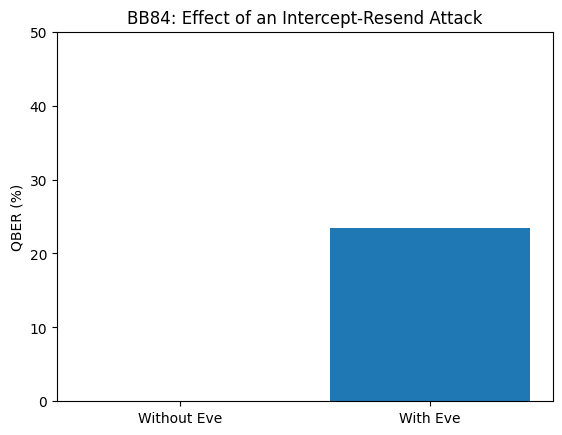

In [15]:
import matplotlib.pyplot as plt

labels = ["Without Eve", "With Eve"]
values = [qber_without_eve, qber_with_eve]

plt.bar(labels, values)
plt.ylabel("QBER (%)")
plt.title("BB84: Effect of an Intercept-Resend Attack")
plt.ylim(0, 50)
plt.show()

In [16]:
runs = 100
n = 1000

qber_results_without_eve = []
qber_results_with_eve = []

for _ in range(runs):
    qber_results_without_eve.append(
        bb84_simulation(n, eve_present=False)
    )
    qber_results_with_eve.append(
        bb84_simulation(n, eve_present=True)
    )

avg_without_eve = sum(qber_results_without_eve) / runs
avg_with_eve = sum(qber_results_with_eve) / runs

print("Number of experiments:", runs)
print("Bits per experiment:", n)
print("Average QBER without Eve:",
      round(avg_without_eve, 2), "%")
print("Average QBER with Eve:",
      round(avg_with_eve, 2), "%")

Number of experiments: 100
Bits per experiment: 1000
Average QBER without Eve: 0.0 %
Average QBER with Eve: 24.85 %


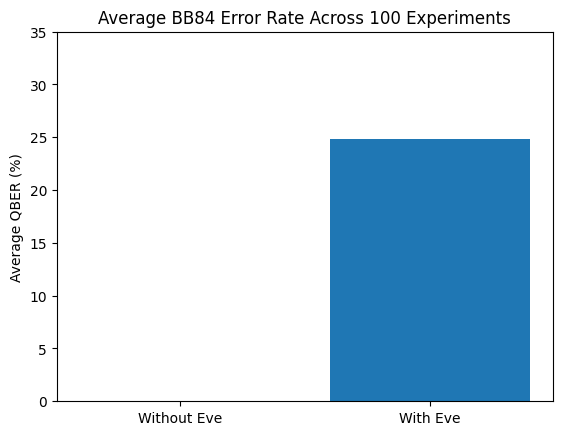

In [17]:
import matplotlib.pyplot as plt

plt.bar(
    ["Without Eve", "With Eve"],
    [avg_without_eve, avg_with_eve]
)
plt.ylabel("Average QBER (%)")
plt.title("Average BB84 Error Rate Across 100 Experiments")
plt.ylim(0, 35)
plt.show()

In [18]:
threshold = 11

print("Security threshold:", threshold, "%")
print("Average QBER without Eve:", round(avg_without_eve, 2), "%")
print("Average QBER with Eve:", round(avg_with_eve, 2), "%")

if avg_without_eve > threshold:
    print("Without Eve: High error rate detected.")
else:
    print("Without Eve: Error rate is within the selected threshold.")

if avg_with_eve > threshold:
    print("With Eve: Suspicious error rate detected!")
else:
    print("With Eve: Error rate is within the selected threshold.")

Security threshold: 11 %
Average QBER without Eve: 0.0 %
Average QBER with Eve: 24.85 %
Without Eve: Error rate is within the selected threshold.
With Eve: Suspicious error rate detected!


In [19]:
bit_sizes = [100, 500, 1000, 5000, 10000]

qber_no_eve = []
qber_eve = []

for size in bit_sizes:
    no_eve_runs = [
        bb84_simulation(size, False) for _ in range(30)
    ]
    eve_runs = [
        bb84_simulation(size, True) for _ in range(30)
    ]

    qber_no_eve.append(sum(no_eve_runs) / len(no_eve_runs))
    qber_eve.append(sum(eve_runs) / len(eve_runs))

for i in range(len(bit_sizes)):
    print(
        "Bits:", bit_sizes[i],
        "| Without Eve:", round(qber_no_eve[i], 2), "%",
        "| With Eve:", round(qber_eve[i], 2), "%"
    )

Bits: 100 | Without Eve: 0.0 % | With Eve: 25.36 %
Bits: 500 | Without Eve: 0.0 % | With Eve: 24.71 %
Bits: 1000 | Without Eve: 0.0 % | With Eve: 24.88 %
Bits: 5000 | Without Eve: 0.0 % | With Eve: 25.03 %
Bits: 10000 | Without Eve: 0.0 % | With Eve: 24.79 %


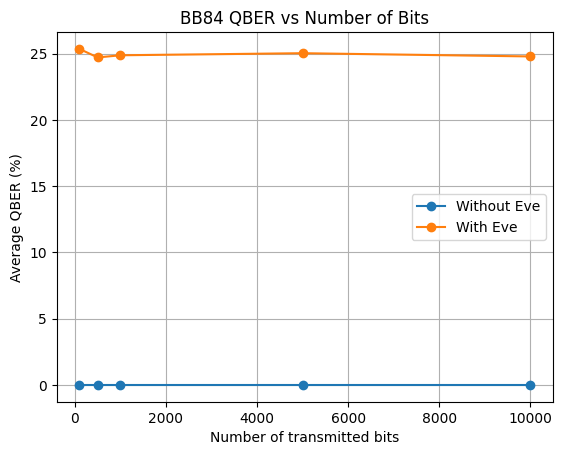

In [20]:
import matplotlib.pyplot as plt

plt.plot(bit_sizes, qber_no_eve, marker='o', label='Without Eve')
plt.plot(bit_sizes, qber_eve, marker='o', label='With Eve')

plt.xlabel("Number of transmitted bits")
plt.ylabel("Average QBER (%)")
plt.title("BB84 QBER vs Number of Bits")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
import pandas as pd
import random
data=[]
for size in [100,500,1000,2000,5000]:
  for eve in [0,1]:
    for _ in range(100):
      qber_value=bb84_simulation(size,eve_present=bool(eve))
      data.append({"number_of_bits":size,"qber":qber_value,"eve_present":eve})
df=pd.DataFrame(data)
print("Dataset created successfully!")
print("Dataset shape:",df.shape)
print(df.head(10))

Dataset created successfully!
Dataset shape: (1000, 3)
   number_of_bits  qber  eve_present
0             100   0.0            0
1             100   0.0            0
2             100   0.0            0
3             100   0.0            0
4             100   0.0            0
5             100   0.0            0
6             100   0.0            0
7             100   0.0            0
8             100   0.0            0
9             100   0.0            0


In [22]:
print("Dataset shape:",df.shape)
print("Total rows:",len(df))
print(df)

Dataset shape: (1000, 3)
Total rows: 1000
     number_of_bits       qber  eve_present
0               100   0.000000            0
1               100   0.000000            0
2               100   0.000000            0
3               100   0.000000            0
4               100   0.000000            0
..              ...        ...          ...
995            5000  24.218123            1
996            5000  25.268603            1
997            5000  25.250903            1
998            5000  25.565146            1
999            5000  25.771971            1

[1000 rows x 3 columns]


In [23]:
print(df.groupby("eve_present")["qber"].describe())
print("Missing values:",df.isnull().sum().sum())

             count       mean       std       min        25%   50%        75%  \
eve_present                                                                     
0            500.0   0.000000  0.000000  0.000000   0.000000   0.0   0.000000   
1            500.0  25.017264  2.960407  9.433962  23.758372  25.0  26.232767   

                   max  
eve_present             
0             0.000000  
1            39.130435  
Missing values: 0


In [24]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X = df[["number_of_bits", "qber"]]
y = df["eve_present"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (800, 2)
X_test shape: (200, 2)


In [25]:
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       1.00      1.00      1.00       100

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200

Confusion Matrix:
[[100   0]
 [  0 100]]


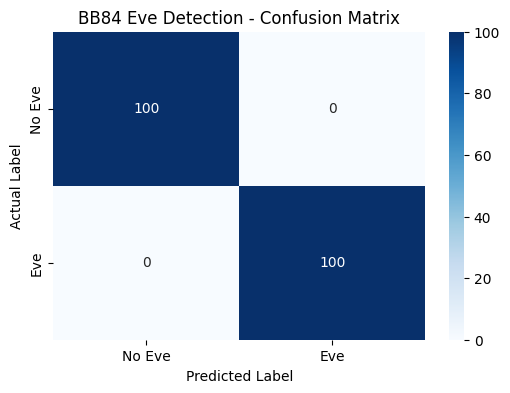

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Eve", "Eve"],
    yticklabels=["No Eve", "Eve"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("BB84 Eve Detection - Confusion Matrix")
plt.show()

In [28]:
try:
    import qiskit
    print("Qiskit version:", qiskit.__version__)
except ImportError:
    print("Qiskit is not installed.")

try:
    import qiskit_machine_learning
    print("Qiskit Machine Learning is installed.")
except ImportError:
    print("Qiskit Machine Learning is not installed.")

Qiskit version: 2.5.2
Qiskit Machine Learning is not installed.


In [29]:
%pip install qiskit qiskit-machine-learning

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.3/282.3 kB 1.5 MB/s eta 0:00:00


In [30]:
import qiskit
import qiskit_machine_learning

print("Qiskit version:", qiskit.__version__)
print("Qiskit Machine Learning installed successfully!")

Qiskit version: 2.5.2
Qiskit Machine Learning installed successfully!


In [31]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X = df[["qber", "number_of_bits"]].copy()
y = df["eve_present"]

scaler = MinMaxScaler(feature_range=(0, 3.14159))
X_scaled = scaler.fit_transform(X)

X_train_q, X_test_q, y_train_q, y_test_q = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train_q))
print("Testing samples:", len(X_test_q))
print("Number of quantum input features:", X_train_q.shape[1])

Training samples: 800
Testing samples: 200
Number of quantum input features: 2


In [32]:
from qiskit.circuit.library import zz_feature_map

feature_map = zz_feature_map(
    feature_dimension=2,
    reps=2,
    entanglement="linear"
)

print(feature_map.draw(output="text"))

   ┌───┐┌───────────┐                                          ┌───┐»
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■──┤ H ├»
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐├───┤»
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├┤ H ├»
   └───┘└───────────┘└───┘└──────────────────────────────┘└───┘└───┘»
«   ┌───────────┐                                          
«0: ┤ P(2*x[0]) ├──■────────────────────────────────────■──
«   ├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐
«1: ┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├
«   └───────────┘└───┘└──────────────────────────────┘└───┘


In [33]:
from qiskit_machine_learning.state_fidelities import ComputeUncompute
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler()

fidelity = ComputeUncompute(sampler=sampler)

quantum_kernel = FidelityQuantumKernel(
    feature_map=feature_map,
    fidelity=fidelity
)

print("Quantum kernel created successfully!")

Quantum kernel created successfully!


In [34]:
from qiskit_machine_learning.algorithms import QSVC
from sklearn.metrics import accuracy_score, classification_report

X_train_small, _, y_train_small, _ = train_test_split(
    X_train_q, y_train_q,
    train_size=min(100, len(X_train_q)),
    random_state=42,
    stratify=y_train_q
)

X_test_small, _, y_test_small, _ = train_test_split(
    X_test_q, y_test_q,
    train_size=min(40, len(X_test_q)),
    random_state=42,
    stratify=y_test_q
)

qsvc = QSVC(quantum_kernel=quantum_kernel)
qsvc.fit(X_train_small, y_train_small)

y_pred_q = qsvc.predict(X_test_small)

print("QSVM accuracy:",
      round(accuracy_score(y_test_small, y_pred_q) * 100, 2), "%")
print(classification_report(y_test_small, y_pred_q))

QSVM accuracy: 97.5 %
              precision    recall  f1-score   support

           0       0.95      1.00      0.98        20
           1       1.00      0.95      0.97        20

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40



In [35]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X_raw = df[["qber", "number_of_bits"]]
y_q = df["eve_present"]

X_train_raw, X_test_raw, y_train_q, y_test_q = train_test_split(
    X_raw,
    y_q,
    test_size=0.2,
    random_state=42,
    stratify=y_q
)

scaler_q = MinMaxScaler(feature_range=(0, 3.14159))

X_train_q = scaler_q.fit_transform(X_train_raw)
X_test_q = scaler_q.transform(X_test_raw)

print("Training samples:", len(X_train_q))
print("Testing samples:", len(X_test_q))
print("Training features:", X_train_q.shape[1])
print("Data preparation completed.")

Training samples: 800
Testing samples: 200
Training features: 2
Data preparation completed.


In [36]:
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.state_fidelities import ComputeUncompute
from qiskit_machine_learning.kernels import FidelityQuantumKernel

sampler = StatevectorSampler()
fidelity = ComputeUncompute(sampler=sampler)

quantum_kernel = FidelityQuantumKernel(
    feature_map=feature_map,
    fidelity=fidelity
)

print("Quantum kernel created successfully!")

Quantum kernel created successfully!


In [38]:
from qiskit_machine_learning.algorithms import QSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Use a smaller dataset first to keep kernel calculations manageable
X_train_small, _, y_train_small, _ = train_test_split(
    X_train_q,
    y_train_q,
    train_size=min(100, len(X_train_q)),
    random_state=42,
    stratify=y_train_q
)

X_test_small, _, y_test_small, _ = train_test_split(
    X_test_q,
    y_test_q,
    train_size=min(40, len(X_test_q)),
    random_state=42,
    stratify=y_test_q
)

qsvc = QSVC(quantum_kernel=quantum_kernel)
qsvc.fit(X_train_small, y_train_small)

y_pred_q = qsvc.predict(X_test_small)

print("QSVM Accuracy:",
      round(accuracy_score(y_test_small, y_pred_q) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test_small, y_pred_q, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_small, y_pred_q))

QSVM Accuracy: 97.5 %

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.98        20
           1       1.00      0.95      0.97        20

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40


Confusion Matrix:
[[20  0]
 [ 1 19]]


In [39]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

classical_svm = SVC(kernel="rbf")

classical_svm.fit(X_train_small, y_train_small)

y_pred_svm = classical_svm.predict(X_test_small)

print("Classical SVM Accuracy:",
      round(accuracy_score(y_test_small, y_pred_svm) * 100, 2), "%")
print("Precision:",
      round(precision_score(y_test_small, y_pred_svm, zero_division=0), 3))
print("Recall:",
      round(recall_score(y_test_small, y_pred_svm, zero_division=0), 3))
print("F1-score:",
      round(f1_score(y_test_small, y_pred_svm, zero_division=0), 3))

Classical SVM Accuracy: 100.0 %
Precision: 1.0
Recall: 1.0
F1-score: 1.0


In [40]:
results = pd.DataFrame({
    "Model": ["Quantum SVM", "Classical SVM"],
    "Accuracy (%)": [
        accuracy_score(y_test_small, y_pred_q) * 100,
        accuracy_score(y_test_small, y_pred_svm) * 100
    ],
    "F1-score": [
        f1_score(y_test_small, y_pred_q, zero_division=0),
        f1_score(y_test_small, y_pred_svm, zero_division=0)
    ]
})

print(results.round(3).to_string(index=False))

        Model  Accuracy (%)  F1-score
  Quantum SVM          97.5     0.974
Classical SVM         100.0     1.000


In [41]:
from sklearn.metrics import classification_report

print("QSVM Results")
print(classification_report(
    y_test_small, y_pred_q, zero_division=0
))

print("Classical SVM Results")
print(classification_report(
    y_test_small, y_pred_svm, zero_division=0
))

QSVM Results
              precision    recall  f1-score   support

           0       0.95      1.00      0.98        20
           1       1.00      0.95      0.97        20

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40

Classical SVM Results
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



In [42]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, f1_score
from qiskit_machine_learning.algorithms import QSVC
import pandas as pd
import numpy as np

repeated_results = []

for seed in range(5):
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        df[["qber", "number_of_bits"]],
        df["eve_present"],
        test_size=0.2,
        random_state=seed,
        stratify=df["eve_present"]
    )

    X_train_small, _, y_train_small, _ = train_test_split(
        X_train_raw,
        y_train,
        train_size=100,
        random_state=seed,
        stratify=y_train
    )

    X_test_small, _, y_test_small, _ = train_test_split(
        X_test_raw,
        y_test,
        train_size=40,
        random_state=seed,
        stratify=y_test
    )

    scaler = MinMaxScaler(feature_range=(0, np.pi))
    X_train_scaled = scaler.fit_transform(X_train_small)
    X_test_scaled = scaler.transform(X_test_small)

    classical = SVC(kernel="rbf")
    classical.fit(X_train_scaled, y_train_small)
    pred_classical = classical.predict(X_test_scaled)

    quantum = QSVC(quantum_kernel=quantum_kernel)
    quantum.fit(X_train_scaled, y_train_small)
    pred_quantum = quantum.predict(X_test_scaled)

    repeated_results.append({
        "Run": seed + 1,
        "QSVM Accuracy (%)": accuracy_score(
            y_test_small, pred_quantum
        ) * 100,
        "QSVM Eve Recall (%)": recall_score(
            y_test_small, pred_quantum, zero_division=0
        ) * 100,
        "Classical SVM Accuracy (%)": accuracy_score(
            y_test_small, pred_classical
        ) * 100,
        "Classical SVM Eve Recall (%)": recall_score(
            y_test_small, pred_classical, zero_division=0
        ) * 100
    })

results_df = pd.DataFrame(repeated_results)
print(results_df.round(2).to_string(index=False))
print("\nAverage results across 5 runs:")
print(results_df.drop(columns="Run").mean().round(2))

 Run  QSVM Accuracy (%)  QSVM Eve Recall (%)  Classical SVM Accuracy (%)  Classical SVM Eve Recall (%)
   1               95.0                 90.0                       100.0                         100.0
   2              100.0                100.0                       100.0                         100.0
   3               90.0                 80.0                       100.0                         100.0
   4               87.5                 75.0                       100.0                         100.0
   5               97.5                 95.0                       100.0                         100.0

Average results across 5 runs:
QSVM Accuracy (%)                94.0
QSVM Eve Recall (%)              88.0
Classical SVM Accuracy (%)      100.0
Classical SVM Eve Recall (%)    100.0
dtype: float64
